In [ ]:

import numpy as np
from datascience import *
import math

# These lines do some fancy plotting magic
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')
import warnings
warnings.simplefilter('ignore', FutureWarning)
from matplotlib import patches
from ipywidgets import interact, interactive, fixed
import ipywidgets as widgets

## Our sample
On Monday, we counted Skittles.  Here are the counts from our entire class

In [ ]:
link = 'https://docs.google.com/spreadsheets/d/12EMZTyOv-k1r6mg3BUm9uuKKAfPtb2Cxyv7z3_MRtq8/export?format=csv'

our_skittles = Table().read_table(link).drop('Timestamp')
our_skittles


red_total = sum(our_skittles.column("Red"))
yellow_total = sum(our_skittles.column("Yellow"))
purple_total = sum(our_skittles.column("Purple"))
orange_total = sum(our_skittles.column("Orange"))
green_total = sum(our_skittles.column("Green"))
grand_total = red_total + yellow_total + purple_total + orange_total + green_total

colors = make_array('Red', 'Yellow', 'Purple', 'Orange', 'Green')
counts = make_array(red_total, yellow_total, purple_total, orange_total, green_total)
summary = Table().with_columns('Color', colors, 'Count', counts)
summary


## Turn the counts into a table with one row per Skittle.

In [ ]:

# Each row is one observed candy in our original sample.
class_skittles = Table().with_column('Color', np.repeat(colors, counts))
class_skittles.num_rows, class_skittles
class_skittles.show()

### Discuss: What is our population? What is our sample? What population parameter are we estimating?

population: ,,,
sample: ...
parameter we are estimating: ...

In [ ]:
# Calculate our original sample percentage of red Skittles.
red = class_skittles.column('Color') == 'Red'
red_percentage = sum(red) / len(red) * 100
print('Sample percentage red:', round(red_percentage, 2), '%')

### One bootstrap resample 
We only have one original sample. A bootstrap resample draws the same number of rows with replacement from that sample.

Predict: Will every candy appear exactly once? Will every resample give the same percentage red?

What do you think?  Write your answer here

In [ ]:
bootstrap_sample = class_skittles.sample()
bootstrap_sample

In [ ]:
bootstrap_sample.group("Color")

### Try it: Run the next cell several times. What changes? What stays the same?

In [ ]:
bootstrap_sample = class_skittles.sample()

#From your guided notes homework -- Find the percentage of red Skittles in your sample
red = ...
red_percentage_bootstrap = ...

print('One bootstrap estimate:', round(red_percentage_bootstrap, 2), '%')

### Your turn: make a reusable function
Complete a function that accepts any table with a Color column and returns the percentage red after one bootstrap resample

In [ ]:
def one_resampled_red_percentage(tbl):
    one_bootstrap_sample = ...  # Resample tbl with replacement
    red = ...                   # Boolean array: which candies are red?
    red_percentage = ...        # Convert the proportion to a percentage
    return red_percentage

In [ ]:
# Test your function when it is complete:
one_resampled_red_percentage(class_skittles)

### Repeat the process
We want a distribution of bootstrap estimates, not just one estimate. Use a for loop and np.append to collect 1,000 estimates.

Before coding: What will the stats array contain when the loop finishes?

In [ ]:
stats = make_array()

for i in np.arange(1000):
    one_percentage = ...  # Call your function from Part 2
    stats = ...           # Append one_percentage to stats

In [ ]:
# When finished, run the following lines to see what your code did
print('Number of bootstrap estimates:', len(stats))
Table().with_column('Estimated Percentage Red', stats).hist('Estimated Percentage Red')

## A 95% bootstrap confidence interval 
The percentile method keeps the middle 95% of bootstrap estimates: 2.5% are below the lower bound and 2.5% are above the upper bound.
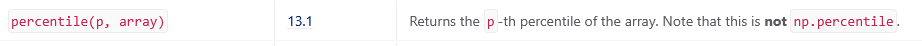

In [ ]:
# Complete after your stats array is working.
lower = percentile(..., stats)  # 2.5th percentile of stats
upper = percentile(..., stats)  # 97.5th percentile of stats

print('95% bootstrap CI for percentage red:', round(lower, 2), 'to', round(upper, 2))

### Interpretation: 
The interval estimates the population percentage of red Skittles, not the percentage of individual candies that fall within the interval.

### Change the statistic 
Homework 7 asks you to estimate a difference in percentages. The bootstrap steps do not change—only the statistic calculated from each resample changes.

For our Skittles, estimate percentage red minus percentage green. A positive difference means red is more common in the sample; a negative difference means green is more common.

In [ ]:
def one_resampled_difference(tbl):
    resample = tbl.sample()
    red = resample.column('Color') == 'Red'
    green = resample.column('Color') == 'Green'
    red_pct = sum(red) / len(red) * 100
    green_pct = sum(green) / len(green) * 100
    return ...  # Red percentage minus green percentage

In [ ]:
# Test your function:
one_resampled_difference(class_skittles)

In [ ]:
differences = make_array()
for i in np.arange(1000):
    one_difference = ...
    differences = ...

In [ ]:
# When finished:
Table().with_column('Red minus Green (percentage points)', differences).hist()
print('95% CI for difference:', percentile(2.5, differences), percentile(97.5, differences))

## Discuss: 
Does your interval include 0? What would a difference of 0 mean? Avoid claiming a population difference from one sample without considering uncertainty.
